# Proyecto final · Olist: del pedido a la reseña

**Equipo:** Ramirez Miguel y [Apellido2 Nombre2]

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.

In [1]:
import warnings
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
CLAVE = getpass("Contraseña: ")
motor = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(CLAVE)}@{HOST}:5432/postgres", poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [2]:
CONSULTA_PEDIDOS = """
WITH resena AS (               -- una sola reseña por pedido: la respondida más recientemente
    SELECT DISTINCT ON (order_id) order_id, review_score
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC
),
articulos AS (                 -- agregados de todos los artículos del pedido
    SELECT oi.order_id,
           COUNT(*)                     AS n_items,
           COUNT(DISTINCT oi.seller_id) AS n_vendedores,
           SUM(oi.price)                AS precio_total,
           SUM(oi.freight_value)        AS flete_total,
           SUM(p.product_weight_g)      AS peso_total_g,
           AVG(p.product_photos_qty)    AS fotos_promedio
    FROM final.order_items oi
    LEFT JOIN final.products p ON p.product_id = oi.product_id
    GROUP BY oi.order_id
),
articulo_1 AS (                -- categoría y estado del vendedor del artículo 1
    SELECT oi.order_id,
           p.product_category_name AS categoria,
           s.seller_state          AS estado_vendedor
    FROM final.order_items oi
    LEFT JOIN final.products p ON p.product_id = oi.product_id
    LEFT JOIN final.sellers  s ON s.seller_id  = oi.seller_id
    WHERE oi.order_item_id = 1
),
pago_principal AS (            -- medio de pago del pago de mayor valor
    SELECT DISTINCT ON (order_id) order_id, payment_type AS tipo_pago
    FROM final.order_payments
    ORDER BY order_id, payment_value DESC, payment_sequential ASC
),
cuotas AS (
    SELECT order_id, MAX(payment_installments) AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
)
SELECT o.order_id,
       o.order_purchase_timestamp,
       o.order_approved_at,
       o.order_delivered_carrier_date,
       o.order_delivered_customer_date,
       o.order_estimated_delivery_date,
       c.customer_state AS estado_cliente,
       a.n_items, a.n_vendedores, a.precio_total, a.flete_total, a.peso_total_g, a.fotos_promedio,
       a1.categoria, a1.estado_vendedor,
       pp.tipo_pago, cu.cuotas_max,
       CASE WHEN r.review_score IN (1, 2) THEN 1 ELSE 0 END AS mala_resena
FROM final.orders o
JOIN final.customers c      ON c.customer_id = o.customer_id
JOIN resena r               ON r.order_id    = o.order_id
JOIN articulos a            ON a.order_id    = o.order_id
LEFT JOIN articulo_1 a1     ON a1.order_id   = o.order_id
LEFT JOIN pago_principal pp ON pp.order_id   = o.order_id
LEFT JOIN cuotas cu         ON cu.order_id   = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
ORDER BY o.order_purchase_timestamp, o.order_id
"""
pedidos = pd.read_sql(CONSULTA_PEDIDOS, motor)
print(pedidos.shape)
pedidos.head()

(77304, 18)


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,SP,3,1,134.97,8.49,3000.0,1.0,beleza_saude,PR,None,NaN,1
1,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,SP,1,1,29.90,15.56,300.0,3.0,relogios_presentes,PR,boleto,1.0,0
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,RS,1,1,21.90,17.19,400.0,1.0,esporte_lazer,SP,boleto,1.0,0
3,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,RS,1,1,36.49,17.24,767.0,1.0,esporte_lazer,SP,boleto,1.0,0
4,d207cc272675637bfed0062edffd0818,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,SP,1,1,119.90,13.56,2050.0,1.0,moveis_decoracao,SP,credit_card,6.0,1


**Decisiones de la consulta (una fila por pedido):**

- **Filtro:** solo `order_status = 'delivered'` con `order_delivered_customer_date IS NOT NULL` y que existan en `final.order_reviews` (el `JOIN` con la CTE `resena` descarta los pedidos sin reseña). Es la población sobre la que el modelo decide: pedidos ya entregados cuya reseña aún no conocemos.
- **Varios artículos:** se agregan en la CTE `articulos`: `n_items` = número de filas en `order_items`, `n_vendedores` = vendedores distintos, `precio_total` y `flete_total` = sumas, `peso_total_g` = suma del peso de los productos y `fotos_promedio` = promedio de fotos. Para las variables que no se pueden sumar (`categoria`, `estado_vendedor`) se toma el **artículo 1** (`order_item_id = 1`), que es el artículo principal del pedido. Así no se pierde información de volumen (más artículos/vendedores = más puntos de falla) y no se duplican pedidos.
- **Varios pagos:** `tipo_pago` es el medio del **pago de mayor valor** (`DISTINCT ON` con `payment_value DESC, payment_sequential ASC` para desempatar), porque representa cómo pagó realmente el cliente la mayor parte del pedido (un voucher pequeño no cambia el perfil). `cuotas_max` = máximo de cuotas del pedido.
- **Varias reseñas:** se queda **la reseña respondida más recientemente** (`DISTINCT ON (order_id) ... ORDER BY order_id, review_answer_timestamp DESC`), que es la opinión final del cliente. De la reseña solo se usa `review_score` para construir la etiqueta `mala_resena` (1 si 1 o 2 estrellas); ninguna otra columna de la reseña entra al modelo.
- **INNER vs LEFT JOIN:** `customers`, `resena` y `articulos` son `INNER` (un pedido sin cliente, sin reseña o sin artículos no cumple el contrato); `products`, `sellers` y los pagos son `LEFT JOIN` para no perder pedidos por un producto sin categoría o un pago faltante: esos huecos quedan como nulos y los imputa el pipeline. Con esto la tabla tiene exactamente las 18 columnas del contrato y 77,304 pedidos.

Esta celda verifica el contrato. Debe imprimir `True`:

In [3]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

In [4]:
print("Faltantes por columna:")
faltantes = pedidos.isna().sum()
display(pd.DataFrame({"faltantes": faltantes, "porcentaje": (faltantes / len(pedidos) * 100).round(3)}))
print(f"Tasa de mala reseña (1-2 estrellas): {pedidos['mala_resena'].mean():.4f}  ->  {pedidos['mala_resena'].sum()} de {len(pedidos)} pedidos")
display(pedidos.describe().T.round(2))

Faltantes por columna:


,faltantes,porcentaje
order_id,0,0.000
order_purchase_timestamp,0,0.000
order_approved_at,14,0.018
order_delivered_carrier_date,1,0.001
order_delivered_customer_date,0,0.000
order_estimated_delivery_date,0,0.000
estado_cliente,0,0.000
n_items,0,0.000
n_vendedores,0,0.000
precio_total,0,0.000


Tasa de mala reseña (1-2 estrellas): 0.1354  ->  10470 de 77304 pedidos


,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,77304,2017-11-16 08:32:22.705551872,2016-09-15 12:16:38,2017-08-10 22:10:47.750000128,2017-12-04 10:14:09.500000,2018-03-05 15:50:30.750000128,2018-05-31 23:51:24,NaN
order_approved_at,77290,2017-11-16 20:01:33.967524608,2016-09-15 12:16:38,2017-08-11 13:23:41.500000,2017-12-05 04:12:00,2018-03-06 03:49:41.500000,2018-06-05 04:51:47,NaN
order_delivered_carrier_date,77303,2017-11-19 17:16:58.680102912,2016-10-08 10:34:01,2017-08-14 20:22:17,2017-12-07 18:27:15,2018-03-08 18:18:33.500000,2018-07-04 06:38:00,NaN
order_delivered_customer_date,77304,2017-11-29 19:19:50.930572800,2016-10-11 13:46:32,2017-08-22 20:43:34,2017-12-20 17:09:45,2018-03-22 20:49:43.249999872,2018-10-11 16:41:14,NaN
order_estimated_delivery_date,77304,2017-12-10 18:56:56.702887424,2016-10-04 00:00:00,2017-09-04 00:00:00,2017-12-29 00:00:00,2018-03-28 00:00:00,2018-08-16 00:00:00,NaN
n_items,77304.0,1.142994,1.0,1.0,1.0,1.0,21.0,0.539446
n_vendedores,77304.0,1.012871,1.0,1.0,1.0,1.0,5.0,0.118646
precio_total,77304.0,136.659358,0.85,45.9,86.9,149.9,13440.0,206.695949
flete_total,77304.0,22.318079,0.0,13.79,16.79,23.7,1002.29,20.504954
peso_total_g,77288.0,2458.9539,2.0,300.0,800.0,2150.0,184400.0,4902.493553


In [5]:
from preparacion import crear_variables as _cv
_v = _cv(pedidos[CONTRATO[:-1]])
raros = {
    "dias_retraso > 30 (llegó más de un mes tarde)": int((_v["dias_retraso"] > 30).sum()),
    "dias_entrega_total > 60": int((_v["dias_entrega_total"] > 60).sum()),
    "dias_transito < 0 (cliente antes que carrier: error de registro)": int((_v["dias_transito"] < 0).sum()),
    "dias_despacho_carrier < 0 (carrier antes de aprobación)": int((_v["dias_despacho_carrier"] < 0).sum()),
    "precio_total > 2,000 BRL": int((pedidos["precio_total"] > 2000).sum()),
    "flete_total = 0 (envío gratis)": int((pedidos["flete_total"] == 0).sum()),
    "ratio_flete_precio > 2 (flete > 2 veces el precio)": int((_v["ratio_flete_precio"] > 2).sum()),
    "cuotas_max = 0": int((pedidos["cuotas_max"] == 0).sum()),
    "n_items > 5": int((pedidos["n_items"] > 5).sum()),
}
display(pd.Series(raros, name="pedidos"))
print("Tasa de mala reseña según entrega tardía:")
display(pedidos.assign(entrega_tardia=_v["entrega_tardia"]).groupby("entrega_tardia")["mala_resena"].agg(["count", "mean"]).round(4))

dias_retraso > 30 (llegó más de un mes tarde)                       322
dias_entrega_total > 60                                             277
dias_transito < 0 (cliente antes que carrier: error de registro)     23
dias_despacho_carrier < 0 (carrier antes de aprobación)             575
precio_total > 2,000 BRL                                             99
flete_total = 0 (envío gratis)                                      333
ratio_flete_precio > 2 (flete > 2 veces el precio)                  273
cuotas_max = 0                                                        2
n_items > 5                                                         189
Name: pedidos, dtype: int64

Tasa de mala reseña según entrega tardía:


,count,mean
entrega_tardia,,
0.0,70643,0.0943
1.0,6661,0.5720


**Faltantes y valores raros (cifras de las salidas de arriba):**

- **Faltantes:** `order_approved_at` 14 (0.018%), `order_delivered_carrier_date` 1 (0.001%), `peso_total_g` 16 (0.021%), `fotos_promedio` 1,239 (1.603%), `categoria` 1,263 (1.634%), `tipo_pago` 1 y `cuotas_max` 1 (0.001%: un pedido sin registro en `order_payments`, que se conserva gracias al `LEFT JOIN`). Las demás columnas no tienen faltantes.
- **Objetivo:** la tasa de mala reseña es **0.1354** (10,470 de 77,304). Llegar tarde la multiplica: 0.0943 en los 70,643 pedidos a tiempo frente a **0.5720** en los 6,661 tardíos.
- **Valores raros:** 322 pedidos llegaron más de 30 días tarde y 277 tardaron más de 60 días en total; 23 tienen `dias_transito < 0` y 575 `dias_despacho_carrier < 0` (errores de registro de fechas); 99 superan 2,000 BRL; 333 tienen flete 0 (envío gratis); en 273 el flete es más de 2 veces el precio; 2 tienen `cuotas_max = 0`; 189 tienen más de 5 artículos. El precio mínimo es 0.85 BRL y el peso mínimo 2 g.

**Cómo los maneja el pipeline:** no se borra ninguna fila (el contrato exige 77,304). `crear_variables` convierte las fechas con `pd.to_datetime(errors="coerce")`, cambia infinitos por `NaN` y nunca falla con `None`. Después, el `ColumnTransformer` imputa la **mediana** en las numéricas y la constante `"desconocido"` en las categóricas, y el `OneHotEncoder(handle_unknown="ignore")` deja pasar categorías nuevas. Los valores extremos (retrasos de meses, precios altos, tránsito negativo por errores de registro) se dejan como están porque son reales y los árboles de XGBoost no se ven afectados por la escala. En la logística se estandarizan con `StandardScaler`.

**Diccionario de variables que crea `preparacion.py` (`crear_variables`):**

| Variable | Cómo se calcula | Qué significa para Olist |
|---|---|---|
| `dias_retraso` | `(order_delivered_customer_date - order_estimated_delivery_date)` en días (decimales) | Días que llegó tarde (+) o antes (−) respecto a la fecha prometida |
| `entrega_tardia` | `1` si `dias_retraso > 0` | El pedido incumplió la promesa de entrega |
| `dias_retraso_pos` | `max(0, dias_retraso)` | Magnitud del atraso (0 si llegó a tiempo) |
| `dias_adelanto` | `max(0, -dias_retraso)` | Cuántos días antes de lo prometido llegó |
| `dias_entrega_total` | `(entrega_cliente - compra)` en días | Tiempo total que esperó el cliente |
| `dias_aprobacion` | `(aprobación - compra)` en días | Demora en aprobar el pago |
| `dias_despacho_carrier` | `(entrega_carrier - aprobación)` en días | Demora del vendedor en despachar |
| `dias_transito` | `(entrega_cliente - entrega_carrier)` en días | Tiempo en manos del transportista |
| `dias_estimados_total` | `(fecha_estimada - compra)` en días | Plazo prometido al cliente |
| `ratio_entrega_estimado` | `dias_entrega_total / max(1, dias_estimados_total)` | Fracción del plazo prometido que se consumió (>1 = tarde) |
| `retraso_carrier` | `1` si `entrega_carrier > fecha_estimada` | El vendedor despachó cuando ya había vencido la promesa |
| `ratio_flete_precio` | `flete_total / max(0.01, precio_total)` | Qué tan caro fue el envío respecto al producto |
| `valor_total_pedido` | `precio_total + flete_total` | Lo que pagó el cliente en total |
| `precio_por_item` | `precio_total / max(1, n_items)` | Precio medio por artículo |
| `flete_por_item` | `flete_total / max(1, n_items)` | Flete medio por artículo |
| `peso_por_item` | `peso_total_g / max(1, n_items)` | Peso medio por artículo (productos voluminosos) |
| `multi_item` | `1` si `n_items > 1` | Pedido con varios artículos |
| `multi_vendedor` | `1` si `n_vendedores > 1` | Pedido con varios vendedores (envíos separados, más riesgo) |
| `vendedores_por_item` | `n_vendedores / max(1, n_items)` | Fragmentación del pedido |
| `mismo_estado` | `1` si `estado_cliente == estado_vendedor` | Envío dentro del mismo estado (más corto) |
| `n_items`, `n_vendedores`, `precio_total`, `flete_total`, `peso_total_g`, `fotos_promedio`, `cuotas_max` | Columnas originales del contrato (numéricas) | Tamaño, valor, peso, calidad del anuncio y financiamiento del pedido |
| `estado_cliente`, `estado_vendedor`, `categoria`, `tipo_pago` | Columnas originales del contrato (categóricas, one-hot) | Geografía, tipo de producto y medio de pago |

Ninguna variable usa la reseña (ni texto, ni su largo, ni `review_creation_date` / `review_answer_timestamp`): todas existen en el momento en que se confirma la entrega.

## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [6]:
from preparacion import crear_variables      # su archivo, en la misma carpeta

In [7]:
import json, shutil, os
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from preparacion import COLUMNAS_NUMERICAS, COLUMNAS_CATEGORICAS

ENTRADAS = CONTRATO[:-1]
datos = pedidos.sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)
corte = int(len(datos) * 0.80)
entreno, valid = datos.iloc[:corte], datos.iloc[corte:]
X_tr, y_tr = entreno[ENTRADAS], entreno["mala_resena"]
X_va, y_va = valid[ENTRADAS], valid["mala_resena"]
for nombre, parte in [("Entrenamiento (80% más antiguo)", entreno), ("Validación (20% más reciente)", valid)]:
    print(f"{nombre}: {len(parte):,} pedidos | {parte['order_purchase_timestamp'].min()} -> "
          f"{parte['order_purchase_timestamp'].max()} | tasa mala reseña = {parte['mala_resena'].mean():.4f}")

Entrenamiento (80% más antiguo): 61,843 pedidos | 2016-09-15 12:16:38 -> 2018-03-22 10:14:00 | tasa mala reseña = 0.1396
Validación (20% más reciente): 15,461 pedidos | 2018-03-22 10:15:19 -> 2018-05-31 23:51:24 | tasa mala reseña = 0.1189


In [8]:
def precision_en_10(y_true, probabilidades):
    k = int(len(y_true) * 0.10)
    orden = np.argsort(-np.asarray(probabilidades))
    return float(np.asarray(y_true)[orden[:k]].mean())

def dias_de_retraso(df):
    return (pd.to_datetime(df["order_delivered_customer_date"]) - pd.to_datetime(df["order_estimated_delivery_date"])).dt.total_seconds() / 86400.0

resultados = {}
resultados["Azar (tasa base)"] = float(y_va.mean())
resultados["Regla del retraso"] = precision_en_10(y_va, dias_de_retraso(X_va).values)
print(f"k = {int(len(y_va) * 0.10)} pedidos (10% de validación)")
for k, v in resultados.items():
    print(f"{k:<20} precision_en_10 = {v:.4f}")

k = 1546 pedidos (10% de validación)
Azar (tasa base)     precision_en_10 = 0.1189
Regla del retraso    precision_en_10 = 0.3855


In [9]:
def crear_preprocesador():
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="desconocido")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))])
    return Pipeline([
        ("variables", FunctionTransformer(crear_variables)),
        ("columnas", ColumnTransformer([("num", numericas, COLUMNAS_NUMERICAS),
                                        ("cat", categoricas, COLUMNAS_CATEGORICAS)])),
    ])

logistica = Pipeline([("prep", crear_preprocesador()),
                      ("modelo", LogisticRegression(max_iter=3000, C=0.5))])
logistica.fit(X_tr, y_tr)
prob_lr = logistica.predict_proba(X_va)[:, 1]
resultados["Regresión logística"] = precision_en_10(y_va, prob_lr)
print(f"Regresión logística  precision_en_10 = {resultados['Regresión logística']:.4f}")

Regresión logística  precision_en_10 = 0.4664


In [10]:
# Búsqueda de hiperparámetros con validación temporal interna:
# dentro del 80% de entrenamiento, el 80% más antiguo ajusta y el 20% más reciente evalúa.
# El conjunto de validación final (20% más reciente) NO se usa para elegir hiperparámetros.
import itertools, time
corte_int = int(len(X_tr) * 0.80)
X_fit, y_fit = X_tr.iloc[:corte_int], y_tr.iloc[:corte_int]
X_tun, y_tun = X_tr.iloc[corte_int:], y_tr.iloc[corte_int:]
prep_tun = crear_preprocesador().fit(X_fit, y_fit)
M_fit, M_tun = prep_tun.transform(X_fit), prep_tun.transform(X_tun)

grilla = [
    dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=1),
    dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5),
    dict(n_estimators=600, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, min_child_weight=5),
    dict(n_estimators=600, max_depth=5, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, min_child_weight=5),
    dict(n_estimators=800, max_depth=5, learning_rate=0.02, subsample=0.8, colsample_bytree=0.6, min_child_weight=10),
    dict(n_estimators=400, max_depth=6, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=10),
    dict(n_estimators=1000, max_depth=4, learning_rate=0.02, subsample=0.7, colsample_bytree=0.6, min_child_weight=20),
]
filas = []
for params in grilla:
    m = XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=42, tree_method="hist", **params)
    m.fit(M_fit, y_fit)
    filas.append({**params, "precision_en_10_tuning": precision_en_10(y_tun, m.predict_proba(M_tun)[:, 1])})
tabla_grilla = pd.DataFrame(filas).sort_values("precision_en_10_tuning", ascending=False)
display(tabla_grilla.round(4))
mejores = {k: (int(v) if k in ("n_estimators", "max_depth", "min_child_weight") else float(v))
           for k, v in tabla_grilla.iloc[0].drop("precision_en_10_tuning").items()}
print("Mejores hiperparámetros:", mejores)

,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,precision_en_10_tuning
5,400,6,0.03,0.8,0.7,10,0.8382
2,600,4,0.03,0.8,0.8,5,0.8333
3,600,5,0.03,0.8,0.8,5,0.8325
6,1000,4,0.02,0.7,0.6,20,0.8325
4,800,5,0.02,0.8,0.6,10,0.8309
1,300,4,0.05,0.8,0.8,5,0.8293
0,300,3,0.05,0.8,0.8,1,0.8261


Mejores hiperparámetros: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.7, 'min_child_weight': 10}


In [11]:
def crear_xgb():
    return Pipeline([("prep", crear_preprocesador()),
                     ("modelo", XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=42, tree_method="hist", **mejores))])

xgb = crear_xgb().fit(X_tr, y_tr)
prob_xgb = xgb.predict_proba(X_va)[:, 1]
resultados["XGBoost"] = precision_en_10(y_va, prob_xgb)

from sklearn.metrics import roc_auc_score
comparacion = pd.DataFrame({"precision_en_10": resultados})
comparacion["mejora_vs_azar (x)"] = comparacion["precision_en_10"] / resultados["Azar (tasa base)"]
comparacion["mejora_vs_retraso (puntos)"] = comparacion["precision_en_10"] - resultados["Regla del retraso"]
comparacion["AUC"] = [np.nan, roc_auc_score(y_va, dias_de_retraso(X_va)), roc_auc_score(y_va, prob_lr), roc_auc_score(y_va, prob_xgb)]
display(comparacion.round(4))

,precision_en_10,mejora_vs_azar (x),mejora_vs_retraso (puntos),AUC
Azar (tasa base),0.1189,1.0000,-0.2666,NaN
Regla del retraso,0.3855,3.2411,0.0000,0.6267
Regresión logística,0.4664,3.9209,0.0809,0.7498
XGBoost,0.4884,4.1058,0.1028,0.7400


Top 10 variables (importancia por ganancia, agrupando one-hot):


,importancia
entrega_tardia,0.6960
dias_retraso_pos,0.0605
categoria,0.0544
multi_item,0.0496
estado_cliente,0.0257
n_items,0.0172
dias_retraso,0.0171
estado_vendedor,0.0148
multi_vendedor,0.0098
n_vendedores,0.0090


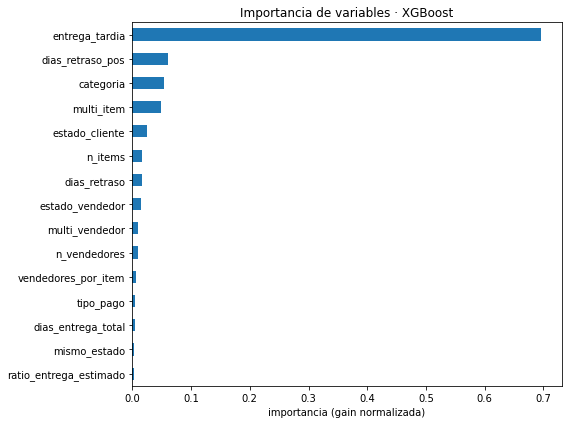

In [12]:
nombres = xgb.named_steps["prep"].named_steps["columnas"].get_feature_names_out()
imp = pd.Series(xgb.named_steps["modelo"].feature_importances_, index=nombres)
# Agrupamos las columnas one-hot por variable original para leer la importancia por variable
original = [n.split("__", 1)[1] for n in nombres]
original = [next((c for c in COLUMNAS_CATEGORICAS if o.startswith(c + "_")), o) for o in original]
imp_var = imp.groupby(original).sum().sort_values(ascending=False)
print("Top 10 variables (importancia por ganancia, agrupando one-hot):")
display(imp_var.head(10).round(4).to_frame("importancia"))
fig, ax = plt.subplots(figsize=(8, 6))
imp_var.head(15)[::-1].plot.barh(ax=ax, color="#1f77b4")
ax.set_title("Importancia de variables · XGBoost"); ax.set_xlabel("importancia (gain normalizada)")
plt.tight_layout(); plt.show()

In [13]:
# ¿Qué pasa en un periodo con muy pocos retrasos? Evaluamos solo los pedidos de validación que llegaron a tiempo
v_tard = crear_variables(X_va)["entrega_tardia"].values
a_tiempo = v_tard == 0
print(f"Pedidos de validación entregados tarde: {int((~a_tiempo).sum())} de {len(a_tiempo)} ({(~a_tiempo).mean():.4f})")
print(f"Tasa de mala reseña a tiempo: {y_va[a_tiempo].mean():.4f} | tarde: {y_va[~a_tiempo].mean():.4f}")
print(f"Subconjunto a tiempo -> XGBoost: {precision_en_10(y_va[a_tiempo], prob_xgb[a_tiempo]):.4f} | "
      f"Regla del retraso: {precision_en_10(y_va[a_tiempo], dias_de_retraso(X_va[a_tiempo]).values):.4f} | "
      f"Azar: {y_va[a_tiempo].mean():.4f}")
mensual = valid.assign(prob=prob_xgb, tarde=v_tard, mes=valid["order_purchase_timestamp"].dt.to_period("M"))
display(mensual.groupby("mes").apply(lambda g: pd.Series({
    "pedidos": len(g), "pct_tarde": g["tarde"].mean(), "tasa_mala": g["mala_resena"].mean(),
    "p10_xgb": precision_en_10(g["mala_resena"], g["prob"]),
})).round(4))

Pedidos de validación entregados tarde: 1159 de 15461 (0.0750)
Tasa de mala reseña a tiempo: 0.0899 | tarde: 0.4771
Subconjunto a tiempo -> XGBoost: 0.2615 | Regla del retraso: 0.0958 | Azar: 0.0899


,pedidos,pct_tarde,tasa_mala,p10_xgb
mes,,,,
2018-03,1987.0,0.1298,0.1610,0.7222
2018-04,6752.0,0.0520,0.1179,0.4859
2018-05,6722.0,0.0818,0.1076,0.4167


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

In [14]:
modelo_final = crear_xgb().fit(pedidos[ENTRADAS], pedidos["mala_resena"])
joblib_dump_path = "modelo_riesgo.joblib"
import joblib
joblib.dump(modelo_final, joblib_dump_path)
probs_full = modelo_final.predict_proba(pedidos[ENTRADAS])[:, 1]
umbral_10 = float(np.quantile(probs_full, 0.90))
with open("umbral_riesgo.json", "w") as f:
    json.dump({"umbral_riesgo_alto": umbral_10, "percentil": 90, "n_pedidos": int(len(pedidos))}, f, indent=2)
os.makedirs("api", exist_ok=True)
for archivo in ["modelo_riesgo.joblib", "umbral_riesgo.json", "preparacion.py"]:
    shutil.copy(archivo, os.path.join("api", archivo))
print(f"Modelo final entrenado con {len(pedidos):,} pedidos y guardado en {joblib_dump_path} "
      f"({os.path.getsize(joblib_dump_path)/1e6:.2f} MB)")
print(f"Umbral del 10% más riesgoso (percentil 90 de las probabilidades): {umbral_10:.4f}")

Modelo final entrenado con 77,304 pedidos y guardado en modelo_riesgo.joblib (1.12 MB)
Umbral del 10% más riesgoso (percentil 90 de las probabilidades): 0.2678


In [15]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]

array([0.8397042 , 0.1150701 , 0.07533574, 0.12310326, 0.27358797],
      dtype=float32)

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?

**1. Mejora sobre la regla del retraso y sobre el azar.** En validación (15,461 pedidos del 2018-03-22 al 2018-05-31, k = 1,546), XGBoost logra `precision_en_10` = **0.4884**, frente a **0.3855** de la regla del retraso (+0.1028, es decir +10.3 puntos) y **0.1189** del azar (**4.11 veces** el azar; la regla da 3.24 veces). La regresión logística queda en 0.4664 (+0.0809 sobre la regla). Dicho simple: de cada 100 llamadas, el modelo encuentra ~49 clientes que iban a poner 1-2 estrellas; la regla, ~39; el azar, ~12. (La logística tiene un AUC algo mayor, 0.7498 vs 0.7400, pero lo que importa al negocio es acertar en el 10% superior, y ahí gana XGBoost.) Hiperparámetros elegidos con validación temporal: `n_estimators=400, max_depth=6, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=10`.

**2. Las tres variables que más pesan** (importancia por ganancia, sumando las columnas one-hot):
- `entrega_tardia` (**0.6960**): incumplir la fecha prometida es la principal causa de enojo; la tasa de mala reseña pasa de 0.0943 a 0.5720 cuando el pedido llega tarde.
- `dias_retraso_pos` (**0.0605**): no es lo mismo un día que tres semanas de atraso; cuanto más tarde, más probable la reseña de 1-2 estrellas.
- `categoria` (**0.0544**): algunas categorías (muebles, artículos voluminosos o frágiles) tienen más productos dañados, incompletos o difíciles de armar, aunque lleguen a tiempo.

**3. Periodo con muy pocos retrasos (como junio-agosto 2018).** En validación solo 1,159 de 15,461 pedidos (7.50%) llegaron tarde. Si miramos solo los pedidos que llegaron a tiempo, el modelo cae a **0.2615** (la regla del retraso a 0.0958 y el azar a 0.0899): sigue siendo casi 3 veces el azar, porque usa categoría, varios vendedores, flete, etc., pero pierde su mejor pista. Por mes: marzo 2018 (12.98% tardíos, tasa de mala reseña 0.1610) da 0.7222; abril (5.20%) 0.4859; mayo (8.18%, tasa 0.1076) 0.4167. Con pocos retrasos hay menos clientes molestos y más de ellos se quejan por el producto (que el modelo no ve), así que la precisión del 10% bajaría y el umbral fijo de 0.2678 marcaría menos del 10% de pedidos. Habría que monitorear la precisión mensual, recalcular el umbral sobre los pedidos recientes y reentrenar.

## Parte 3 · Pregunta abierta

Opción elegida: **3A pronóstico de junio**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

**Por qué 3A:** el equipo de atención al cliente solo puede llamar al 10% de los pedidos de mayor riesgo. Ese 10% es un porcentaje de un volumen que cambia día a día: si en junio entran 230 pedidos diarios, son ~23 llamadas al día; si entran 130, son ~13. Pronosticar los pedidos diarios de junio de 2018 permite **dimensionar cuántos agentes programar cada día** (lunes vs domingo) y anticipar picos, en lugar de reaccionar tarde. Además el modelo de riesgo se aplica sobre esos pedidos cuando se entregan, así que ambos trabajos se complementan.

635 días: 2016-09-04 -> 2018-05-31 | total 80,450 pedidos (todos los estados)


,pedidos_mes,media_diaria
fecha,,
2017-10-31,4631,149.4
2017-11-30,7544,251.5
2017-12-31,5673,183.0
2018-01-31,7269,234.5
2018-02-28,6728,240.3
2018-03-31,7211,232.6
2018-04-30,6939,231.3
2018-05-31,6873,221.7


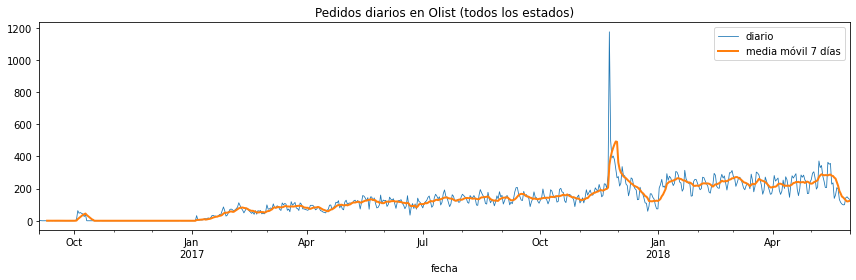

In [16]:
CONSULTA_DIARIA = """
SELECT DATE(order_purchase_timestamp) AS fecha, COUNT(*) AS pedidos
FROM final.orders
WHERE order_purchase_timestamp < '2018-06-01'
GROUP BY 1
ORDER BY 1
"""
diario = pd.read_sql(CONSULTA_DIARIA, motor, parse_dates=["fecha"]).set_index("fecha")["pedidos"].asfreq("D", fill_value=0)
print(f"{len(diario)} días: {diario.index.min().date()} -> {diario.index.max().date()} | total {diario.sum():,} pedidos (todos los estados)")
display(diario.resample("M").agg(["sum", "mean"]).tail(8).round(1).rename(columns={"sum": "pedidos_mes", "mean": "media_diaria"}))
fig, ax = plt.subplots(figsize=(12, 4))
diario.plot(ax=ax, lw=0.8, label="diario"); diario.rolling(7).mean().plot(ax=ax, lw=2, label="media móvil 7 días")
ax.set_title("Pedidos diarios en Olist (todos los estados)"); ax.legend(); plt.tight_layout(); plt.show()

In [17]:
ultimas = diario["2018-04-23":].to_frame("pedidos")
ultimas["dia_semana"] = ultimas.index.day_name()
ultimas["media_7d"] = diario.rolling(7).mean()["2018-04-23":].round(1)
display(ultimas.T)
por_dia = diario["2018-01-01":"2018-05-18"]
print("Mediana por día de la semana (ene - 18 may 2018):")
display(por_dia.groupby(por_dia.index.day_name()).median().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).to_frame("mediana"))
semana_huelga = diario["2018-05-25":"2018-05-31"].mean()
semana_previa = diario["2018-05-04":"2018-05-17"].mean()
print(f"Media 25-31 may: {semana_huelga:.1f} | media 4-17 may: {semana_previa:.1f} | caída: {1 - semana_huelga/semana_previa:.1%}")
madres = diario["2018-05-07":"2018-05-16"]
print("Semana del Día de las Madres (domingo 13-may-2018):")
print(madres.to_frame("pedidos").assign(dia=madres.index.day_name()).T.to_string())

fecha,2018-04-23,2018-04-24,2018-04-25,2018-04-26,2018-04-27,2018-04-28,2018-04-29,2018-04-30,2018-05-01,2018-05-02,...,2018-05-22,2018-05-23,2018-05-24,2018-05-25,2018-05-26,2018-05-27,2018-05-28,2018-05-29,2018-05-30,2018-05-31
pedidos,285,271,284,254,242,169,171,240,256,296,...,199,132,114,104,99,100,143,149,140,133
dia_semana,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Monday,Tuesday,Wednesday,...,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Monday,Tuesday,Wednesday,Thursday
media_7d,239.6,240.3,240.9,235.3,241.7,243.6,239.4,233.0,230.9,232.6,...,218.0,185.9,169.6,150.7,145.0,136.3,127.3,120.1,121.3,124.0


Mediana por día de la semana (ene - 18 may 2018):


,mediana
fecha,
Monday,276.0
Tuesday,264.0
Wednesday,275.5
Thursday,256.5
Friday,225.0
Saturday,184.0
Sunday,202.0


Media 25-31 may: 124.0 | media 4-17 may: 282.9 | caída: 56.2%
Semana del Día de las Madres (domingo 13-may-2018):
fecha   2018-05-07 2018-05-08 2018-05-09 2018-05-10 2018-05-11 2018-05-12 2018-05-13 2018-05-14 2018-05-15 2018-05-16
pedidos        372        331        344        279        247        207        207        364        352        357
dia         Monday    Tuesday  Wednesday   Thursday     Friday   Saturday     Sunday     Monday    Tuesday  Wednesday


**Lectura de las últimas semanas de mayo (cifras de la salida de arriba):**

- **Día de las Madres (domingo 13 de mayo de 2018):** las semanas previas tienen un pico de compras de regalos. Los lunes 7 y 14 de mayo hubo 372 y 364 pedidos, frente a una mediana de 276 para los lunes de enero a mediados de mayo; la media del 4 al 17 de mayo fue **282.9** pedidos/día. Es un efecto puntual que no se repetirá en junio.
- **Huelga de camioneros (21 al 31 de mayo de 2018):** el paro bloqueó carreteras y paralizó la logística de Brasil. La media del 25 al 31 de mayo cayó a **124.0** pedidos/día, una caída de **56.2%** respecto del 4-17 de mayo. La media móvil de 7 días baja de 218.0 (22 de mayo) a 124.0 (31 de mayo).

**Cómo tratamos la anomalía:** si copiáramos la última semana (lo que hace el ingenuo semanal), junio quedaría casi a la mitad del nivel normal. Por eso los días 19-31 de mayo (y Black Friday 2017) se **excluyen** al estimar el nivel por día de la semana, y se usa la **mediana**, que no se deja arrastrar por los días altos del Día de las Madres ni por los bajos de la huelga. La huelga solo se usa para un supuesto explícito: los primeros días de junio arrancan a mitad de camino entre el nivel de huelga y el normal, y vuelven al nivel normal en 10 días.

In [18]:
BLACK_FRIDAY = list(pd.date_range("2017-11-24", "2017-11-27"))
HUELGA = list(pd.date_range("2018-05-19", "2018-05-31"))   # paro de camioneros (21-31 may) y días previos de desabastecimiento
ANOMALIAS = BLACK_FRIDAY + HUELGA

def ingenuo_semanal(hist, h):
    ultima = hist.iloc[-7:].values
    return np.array([ultima[i % 7] for i in range(h)], dtype=float)

def perfil_semanal(hist, h, ventana=56, ponderado=False):
    s = hist.drop(ANOMALIAS, errors="ignore")
    s = s[s.index > s.index.max() - pd.Timedelta(days=ventana)]
    if ponderado:   # media ponderada exponencial (vida media ~ 4 semanas)
        w = np.exp(-(s.index.max() - s.index).days / 28.0)
        perfil = pd.Series(s.values * w).groupby(s.index.dayofweek).sum() / pd.Series(w).groupby(s.index.dayofweek).sum()
    else:           # mediana robusta por día de la semana
        perfil = s.groupby(s.index.dayofweek).median()
    futuro = pd.date_range(hist.index.max() + pd.Timedelta(days=1), periods=h)
    return perfil.reindex(futuro.dayofweek).values.astype(float)

from statsmodels.tsa.holtwinters import ExponentialSmoothing
def holt_winters(hist, h):
    s = hist.drop(ANOMALIAS, errors="ignore").asfreq("D").interpolate().iloc[-180:].astype(float).clip(lower=1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ExponentialSmoothing(s, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=7).fit().forecast(h).values

metodos = {
    "Ingenuo semanal": ingenuo_semanal,
    "Perfil semanal mediana 28d": lambda h_, n: perfil_semanal(h_, n, 28),
    "Perfil semanal mediana 56d": lambda h_, n: perfil_semanal(h_, n, 56),
    "Perfil semanal ponderado 56d": lambda h_, n: perfil_semanal(h_, n, 56, ponderado=True),
    "Holt-Winters amortiguado": holt_winters,
}
# Validación por fecha con origen móvil: cada 7 días desde jul-2017, pronosticamos 30 días hacia adelante
origenes = pd.date_range("2017-06-30", "2018-05-04", freq="7D")
errores, residuos = {m: [] for m in metodos}, []
for o in origenes:
    hist = diario[:o]
    real = diario[o + pd.Timedelta(days=1): o + pd.Timedelta(days=30)]
    real = real[~real.index.isin(BLACK_FRIDAY)]
    futuro = pd.date_range(o + pd.Timedelta(days=1), periods=30)
    for nombre, f in metodos.items():
        pred = pd.Series(f(hist, 30), index=futuro).reindex(real.index)
        errores[nombre].append(np.abs(pred - real).mean())
        if nombre == "Perfil semanal mediana 56d":
            residuos.extend((real / pred).values)
mae = pd.Series({m: np.mean(v) for m, v in errores.items()}).sort_values()
print(f"{len(origenes)} orígenes de validación (30 días cada uno). MAE promedio (pedidos/día):")
display(mae.round(2).to_frame("MAE"))
q10, q90 = np.quantile(residuos, [0.10, 0.90])
print(f"Cuantiles de real/pronóstico (perfil 56d): q10 = {q10:.3f} | q90 = {q90:.3f}")
cobertura_bt = np.mean((np.array(residuos) >= q10) & (np.array(residuos) <= q90))
print(f"Cobertura de la banda en los orígenes de validación: {cobertura_bt:.1%}")

45 orígenes de validación (30 días cada uno). MAE promedio (pedidos/día):


,MAE
Perfil semanal mediana 56d,33.04
Perfil semanal ponderado 56d,33.86
Perfil semanal mediana 28d,35.68
Holt-Winters amortiguado,35.95
Ingenuo semanal,44.35


Cuantiles de real/pronóstico (perfil 56d): q10 = 0.850 | q90 = 1.384
Cobertura de la banda en los orígenes de validación: 80.0%


In [19]:
fechas_junio = pd.date_range("2018-06-01", "2018-06-30", freq="D")
base = perfil_semanal(diario, 30, 56)     # nivel previo a la huelga, por día de la semana
# Supuesto de recuperación: el paro terminó a fines de mayo; asumimos que la demanda vuelve a su nivel
# normal en 10 días, partiendo del punto medio entre el nivel de la semana de huelga y el normal.
nivel_huelga = diario["2018-05-25":"2018-05-31"].sum() / perfil_semanal(diario[:"2018-05-24"], 7, 56).sum()
inicio = (1 + nivel_huelga) / 2
recuperacion = np.minimum(1.0, inicio + (1 - inicio) * np.arange(30) / 10)
pronostico = base * recuperacion
pronostico_junio = pd.DataFrame({
    "fecha": fechas_junio.strftime("%Y-%m-%d"),
    "pronostico": np.round(pronostico, 1),
    "bajo": np.round(pronostico * q10, 1),
    "alto": np.round(pronostico * q90, 1),
})
pronostico_junio.to_csv("pronostico_junio.csv", index=False)
print(f"Nivel de la semana de huelga vs normal: {nivel_huelga:.3f} -> factor inicial de recuperación {inicio:.3f}")
print(f"pronostico_junio.csv: {pronostico_junio.shape[0]} filas | columnas {list(pronostico_junio.columns)}")
print(f"Total junio pronosticado: {pronostico.sum():,.0f} pedidos (media {pronostico.mean():.1f}/día; banda 80%: "
      f"{(pronostico*q10).sum():,.0f} - {(pronostico*q90).sum():,.0f})")
display(pronostico_junio.head(10))

Nivel de la semana de huelga vs normal: 0.519 -> factor inicial de recuperación 0.759
pronostico_junio.csv: 30 filas | columnas ['fecha', 'pronostico', 'bajo', 'alto']
Total junio pronosticado: 6,779 pedidos (media 226.0/día; banda 80%: 5,761 - 9,382)


,fecha,pronostico,bajo,alto
0,2018-06-01,166.3,141.3,230.1
1,2018-06-02,130.4,110.9,180.5
2,2018-06-03,164.3,139.7,227.4
3,2018-06-04,233.7,198.6,323.4
4,2018-06-05,223.3,189.8,309.1
5,2018-06-06,248.1,210.8,343.3
6,2018-06-07,235.4,200.1,325.8
7,2018-06-08,203.2,172.7,281.2
8,2018-06-09,158.5,134.7,219.3
9,2018-06-10,198.6,168.8,274.9


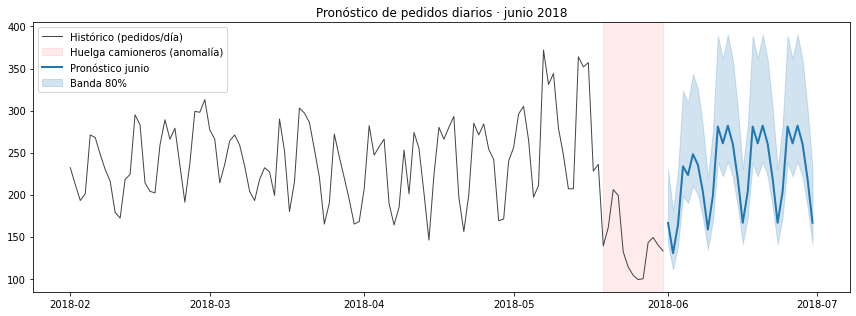

In [20]:
fig, ax = plt.subplots(figsize=(12, 4.5))
reciente = diario["2018-02-01":]
ax.plot(reciente.index, reciente.values, color="#444", lw=1, label="Histórico (pedidos/día)")
ax.axvspan(pd.Timestamp("2018-05-19"), pd.Timestamp("2018-05-31"), color="red", alpha=0.08, label="Huelga camioneros (anomalía)")
ax.plot(fechas_junio, pronostico_junio["pronostico"], color="#1f77b4", lw=2, label="Pronóstico junio")
ax.fill_between(fechas_junio, pronostico_junio["bajo"], pronostico_junio["alto"], color="#1f77b4", alpha=0.2, label="Banda 80%")
ax.set_title("Pronóstico de pedidos diarios · junio 2018"); ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [21]:
# Archivos de apoyo para la página de pronóstico de la app
os.makedirs("app", exist_ok=True)
shutil.copy("pronostico_junio.csv", "app/pronostico_junio.csv")
diario.rename_axis("fecha").reset_index().assign(fecha=lambda d: d["fecha"].dt.strftime("%Y-%m-%d")).to_csv("app/serie_diaria.csv", index=False)
mae.round(2).rename_axis("metodo").reset_index(name="MAE").to_csv("app/validacion_pronostico.csv", index=False)
pd.DataFrame({"metrica": ["mae_modelo", "mae_ingenuo", "q10", "q90", "cobertura_validacion"],
              "valor": [mae["Perfil semanal mediana 56d"], mae["Ingenuo semanal"], q10, q90, cobertura_bt]}).to_csv("app/metricas_pronostico.csv", index=False)
print("Copiados a app/: pronostico_junio.csv, serie_diaria.csv, validacion_pronostico.csv, metricas_pronostico.csv")

Copiados a app/: pronostico_junio.csv, serie_diaria.csv, validacion_pronostico.csv, metricas_pronostico.csv


**Método y validación.** Probamos 4 métodos contra el ingenuo semanal con **validación por fecha de origen móvil**: 45 orígenes (cada 7 días, del 2017-06-30 al 2018-05-04), pronosticando 30 días cada vez. MAE promedio (pedidos/día): perfil semanal con mediana de 56 días **33.04**, perfil ponderado 33.86, mediana de 28 días 35.68, Holt-Winters amortiguado 35.95 e **ingenuo semanal 44.35**. Elegimos el **perfil semanal (mediana de los últimos 56 días por día de la semana, sin anomalías)**: tiene el menor MAE, 25.5% menos que el ingenuo y por debajo de la meta de 45.

**Intervalo del 80%.** En esos 45 orígenes calculamos la razón real/pronóstico; sus cuantiles 10% y 90% son **0.850** y **1.384**. Multiplicando el pronóstico por ellos se obtienen `bajo` y `alto`; en validación la banda cubrió el **80.0%** de los días (dentro del rango pedido de 65%-95%). La banda es asimétrica hacia arriba porque los picos (campañas, feriados) son más frecuentes que las caídas.

**Pronóstico.** El nivel de la semana de huelga fue 0.519 del normal, así que el 1 de junio arranca con un factor de 0.759 que sube linealmente hasta 1 en 10 días. Resultado: **6,779 pedidos en junio** (media **226.0 por día**; banda del 80%: 5,761 a 9,382). Por ejemplo, el sábado 2 de junio se esperan 130.4 pedidos y el miércoles 6 de junio 248.1. `pronostico_junio.csv` tiene 30 filas con `fecha, pronostico, bajo, alto`.

**Supuestos:** la huelga termina a fines de mayo y la demanda se recupera en ~10 días; no hay campañas grandes en junio (el Mundial empieza el 14 de junio y podría bajar algunos días); el patrón semanal se mantiene (más pedidos lunes-jueves, menos sábados).

**Uso para atención al cliente:** con 226.0 pedidos/día en promedio, el 10% equivale a unas 23 llamadas diarias; los días fuertes (miércoles 6: 248.1) piden ~25 llamadas y los sábados de la primera semana ~13. Conviene planificar con el valor `alto` para no quedarse corto.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [22]:
!pip install -q transformers

In [23]:
from transformers import pipeline as hf_pipeline
CONSULTA_COMENTARIOS = """
SELECT review_id, order_id, review_score, review_comment_message
FROM final.order_reviews
WHERE review_comment_message IS NOT NULL AND TRIM(review_comment_message) <> ''
ORDER BY review_id, order_id
"""
comentarios = pd.read_sql(CONSULTA_COMENTARIOS, motor)
muestra = comentarios.sample(n=1200, random_state=42).reset_index(drop=True)
print(f"Comentarios con texto: {len(comentarios):,} | muestra: {len(muestra):,} (random_state=42)")
clasificador = hf_pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                           truncation=True, max_length=512)
salida = clasificador(muestra["review_comment_message"].tolist(), batch_size=32)
muestra["sentimiento_modelo"] = [s["label"].lower() for s in salida]
muestra["confianza_modelo"] = [round(s["score"], 4) for s in salida]
muestra["sentimiento_estrellas"] = pd.cut(muestra["review_score"], [0, 2, 3, 5], labels=["negative", "neutral", "positive"]).astype(str)
muestra["coincide"] = muestra["sentimiento_modelo"] == muestra["sentimiento_estrellas"]
muestra[["review_score", "sentimiento_estrellas", "sentimiento_modelo", "confianza_modelo", "review_comment_message"]].head()

Comentarios con texto: 33,592 | muestra: 1,200 (random_state=42)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15903.70it/s]

,review_score,sentimiento_estrellas,sentimiento_modelo,confianza_modelo,review_comment_message
0,5,positive,positive,0.4960,Recomendo
1,5,positive,positive,0.8222,eu recomendo otimo trabalho e produto\r\nbom ....
2,1,negative,negative,0.7096,"Produto nao entregue, enviado um dos itens da ..."
3,1,negative,negative,0.7477,Meu produto só chegou o shampoo o condicionado...
4,5,positive,positive,0.8158,muito bom


In [24]:
orden = ["negative", "neutral", "positive"]
conteos = pd.crosstab(muestra["sentimiento_estrellas"], muestra["sentimiento_modelo"], margins=True,
                      rownames=["estrellas"], colnames=["RoBERTa"]).reindex(index=orden + ["All"], columns=orden + ["All"], fill_value=0)
porcentajes = (pd.crosstab(muestra["sentimiento_estrellas"], muestra["sentimiento_modelo"], normalize="index",
                           rownames=["estrellas"], colnames=["RoBERTa"]).reindex(index=orden, columns=orden, fill_value=0) * 100).round(1)
print("Conteos:"); display(conteos)
print("Porcentaje por fila (de cada grupo de estrellas, qué predijo el modelo):"); display(porcentajes)
coincidencia_global = muestra["coincide"].mean()
por_categoria = muestra.groupby("sentimiento_estrellas")["coincide"].agg(["count", "mean"]).reindex(orden)
print(f"Coincidencia global: {coincidencia_global:.1%} ({int(muestra['coincide'].sum())} de {len(muestra)})")
display((por_categoria.assign(mean=lambda d: (d["mean"] * 100).round(1))).rename(columns={"count": "comentarios", "mean": "% coincidencia"}))

Conteos:


RoBERTa,negative,neutral,positive,All
estrellas,,,,
negative,217,134,7,358
neutral,43,36,21,100
positive,38,132,572,742
All,298,302,600,1200


Porcentaje por fila (de cada grupo de estrellas, qué predijo el modelo):


RoBERTa,negative,neutral,positive
estrellas,,,
negative,60.6,37.4,2.0
neutral,43.0,36.0,21.0
positive,5.1,17.8,77.1


Coincidencia global: 68.8% (825 de 1200)


,comentarios,% coincidencia
sentimiento_estrellas,,
negative,358,60.6
neutral,100,36.0
positive,742,77.1


In [25]:
def tipo_desacuerdo(fila):
    e, m = fila["sentimiento_estrellas"], fila["sentimiento_modelo"]
    if e == m:
        return "coincide"
    if {e, m} == {"negative", "positive"}:
        return "contradicción fuerte (positivo vs negativo)"
    return f"estrellas {e} / texto {m}"
muestra["tipo_desacuerdo"] = muestra.apply(tipo_desacuerdo, axis=1)
desacuerdos = muestra[~muestra["coincide"]]
print(f"Desacuerdos: {len(desacuerdos)} de {len(muestra)}")
display(desacuerdos["tipo_desacuerdo"].value_counts().to_frame("comentarios"))

# Análisis manual (lectura del texto en portugués) de desacuerdos concretos de la muestra
ANALISIS_MANUAL = {
    "9b183b9ed7bcab6bf37a5022492c22b4": {"traduccion": "El plazo de entrega se respetó de forma sorprendente. Saludos.",
        "veredicto": "Error del modelo", "explicacion": "Elogio claro; el modelo asocia 'prazo' y 'surpreendente' a quejas (sesgo de vocabulario logístico)."},
    "4bebff15fbb347cea8de0087b29e5dcd": {"traduccion": "Primero, la tienda es EXCELENTE para comprar, no hay burocracia; la tienda socia cumple y el producto llegó a tiempo.",
        "veredicto": "Error del modelo", "explicacion": "Texto totalmente positivo escrito en MAYÚSCULAS; el modelo (entrenado en tweets) interpreta las mayúsculas como enojo."},
    "4991c3612ddb56bf3c9ec48b1fe46e7b": {"traduccion": "MUY BUENO",
        "veredicto": "Error del cliente", "explicacion": "Pone 2 estrellas pero escribe 'muy bueno': probablemente confundió la escala de estrellas."},
    "f4e46354e0f577109f610bde000e2ed2": {"traduccion": "Creo que es una tienda maravillosa que tiene todo lo que necesitamos.",
        "veredicto": "Error del cliente", "explicacion": "2 estrellas con un comentario 100% positivo: las estrellas no reflejan lo que dice."},
    "0303804af92daa119d4dfa93e017fb7c": {"traduccion": "Compré un camión rojo de regalo para mi hijo y recibí un cepillo de dientes. Quiero que se resuelva rápido, el cumpleaños ya pasó...",
        "veredicto": "Error del modelo", "explicacion": "Queja grave (producto equivocado) narrada sin palabras negativas explícitas; el modelo no capta el contexto."},
    "e13c9cfd4ababd7fc130baffafa97fce": {"traduccion": "Compra hecha el 03-02-2018, sigo esperando mi compra, pido que la agilicen, gracias, Luiz.",
        "veredicto": "Error del modelo", "explicacion": "Reclamo por no recibir el pedido; el tono cortés ('grato') engaña al modelo."},
    "b6993906c9038a9d51d6e6a3f1b3833a": {"traduccion": "La entrega estaba prevista hasta el 12/12/17 y hasta ahora no se ha entregado.",
        "veredicto": "Error del modelo", "explicacion": "Queja factual sin adjetivos: el modelo la ve neutra, pero es un incumplimiento (1 estrella justificada)."},
    "3e2077f5e653f7feb84021b9aeae83a7": {"traduccion": "Producto muy bueno, pero el plazo no se cumplió.",
        "veredicto": "Error del cliente", "explicacion": "Pone 5 estrellas pese a quejarse del retraso: comentario mixto, el modelo se queda con la queja."},
    "e68610a46d7e86569d5a28aedf4f4c4a": {"traduccion": "Molestó un poco por el retraso. Aproximadamente 20 días. Pero valió la pena.",
        "veredicto": "Ambiguo (texto mixto)", "explicacion": "4 estrellas con queja de 20 días de retraso: el texto revela un problema que las estrellas esconden."},
    "5d27aeada60862a6042536ebf9737b85": {"traduccion": "Esta es mi primera compra. Espero tener más suerte la próxima.",
        "veredicto": "Error del modelo", "explicacion": "Ironía/decepción ('más suerte la próxima'); el modelo lo lee como deseo positivo."},
    "8bbb78caa68fa539b1f1a8a353f20e2d": {"traduccion": "Siempre me gustó comprar en la tienda. ¡Confío en la seriedad de esta tienda!",
        "veredicto": "Error del cliente", "explicacion": "3 estrellas con comentario muy positivo: las estrellas subestiman la satisfacción."},
    "25b72a957812c02f4cfa3d3cb6aad18e": {"traduccion": "Producto conforme a lo solicitado.",
        "veredicto": "Error del modelo", "explicacion": "Texto muy corto y descriptivo: el modelo lo ve neutro aunque es una aprobación (5 estrellas)."},
}

muestra["traduccion"] = muestra["review_id"].map(lambda r: ANALISIS_MANUAL.get(r, {}).get("traduccion", ""))
muestra["quien_se_equivoco"] = muestra["review_id"].map(lambda r: ANALISIS_MANUAL.get(r, {}).get("veredicto", ""))
muestra["explicacion"] = muestra["review_id"].map(lambda r: ANALISIS_MANUAL.get(r, {}).get("explicacion", ""))
pd.set_option("display.max_colwidth", 160)
display(muestra[muestra["quien_se_equivoco"] != ""][["review_score", "sentimiento_modelo", "review_comment_message",
                                                     "traduccion", "quien_se_equivoco", "explicacion"]])
print(muestra.loc[muestra["quien_se_equivoco"] != "", "quien_se_equivoco"].value_counts())

Desacuerdos: 375 de 1200


,comentarios
tipo_desacuerdo,
estrellas negative / texto neutral,134
estrellas positive / texto neutral,132
contradicción fuerte (positivo vs negativo),45
estrellas neutral / texto negative,43
estrellas neutral / texto positive,21


,review_score,sentimiento_modelo,review_comment_message,traduccion,quien_se_equivoco,explicacion
13,5,neutral,Produto conforme solicitado.,Producto conforme a lo solicitado.,Error del modelo,Texto muy corto y descriptivo: el modelo lo ve neutro aunque es una aprobación (5 estrellas).
28,1,neutral,"A previsão para entrega seria para até 12/12/17, e até o momento não foi entregue!",La entrega estaba prevista hasta el 12/12/17 y hasta ahora no se ha entregado.,Error del modelo,"Queja factual sin adjetivos: el modelo la ve neutra, pero es un incumplimiento (1 estrella justificada)."
89,5,negative,Produto muito bom mais o prazo nao.foi cumprido,"Producto muy bueno, pero el plazo no se cumplió.",Error del cliente,"Pone 5 estrellas pese a quejarse del retraso: comentario mixto, el modelo se queda con la queja."
98,4,negative,"PRIMEIRAMENTE O lannister.COM É EXCELENTE PARA SE COMPRAR, POIS NÃO HÁ BUROCRACIA PARA RESOLVER QUALQUER PENDÊNCIA. A LOJA PARCEIRO TAMBÉM CORRESPONDE COM O...","Primero, la tienda es EXCELENTE para comprar, no hay burocracia; la tienda socia cumple y el producto llegó a tiempo.",Error del modelo,Texto totalmente positivo escrito en MAYÚSCULAS; el modelo (entrenado en tweets) interpreta las mayúsculas como enojo.
114,5,negative,O prazo de entrega foi respeitado de forma surpreendente. Abs.,El plazo de entrega se respetó de forma sorprendente. Saludos.,Error del modelo,Elogio claro; el modelo asocia 'prazo' y 'surpreendente' a quejas (sesgo de vocabulario logístico).
147,3,positive,esta e minha primeira compra. espero ter maior sorte na proxima,Esta es mi primera compra. Espero tener más suerte la próxima.,Error del modelo,Ironía/decepción ('más suerte la próxima'); el modelo lo lee como deseo positivo.
157,4,negative,Incomodou um pouco por conta do atraso. Aproximados 20 dias. Mas valeu.,Molestó un poco por el retraso. Aproximadamente 20 días. Pero valió la pena.,Ambiguo (texto mixto),4 estrellas con queja de 20 días de retraso: el texto revela un problema que las estrellas esconden.
313,3,positive,Sempre gostei de comprar no baratheon. Confio na seriedade dessa loja!,Siempre me gustó comprar en la tienda. ¡Confío en la seriedad de esta tienda!,Error del cliente,3 estrellas con comentario muy positivo: las estrellas subestiman la satisfacción.
489,2,positive,MUITO BOM,MUY BUENO,Error del cliente,Pone 2 estrellas pero escribe 'muy bueno': probablemente confundió la escala de estrellas.
732,1,positive,compra efetuada em 03=02- 2018\r\nfico no aguardo da minha compra\r\npeço agilizar\r\ngrato luiz,"Compra hecha el 03-02-2018, sigo esperando mi compra, pido que la agilicen, gracias, Luiz.",Error del modelo,Reclamo por no recibir el pedido; el tono cortés ('grato') engaña al modelo.


quien_se_equivoco
Error del modelo         7
Error del cliente        4
Ambiguo (texto mixto)    1
Name: count, dtype: int64


In [26]:
import re
texto = muestra["review_comment_message"].str.lower()
temas = {
    "no recibió / no llegó": r"n[aã]o (recebi|chegou|foi entregue)|nao recebi|não recebi",
    "atraso / demora": r"atras|demor|prazo",
    "producto defectuoso / distinto": r"defeito|quebrad|errad|diferente|falt",
    "elogio a la rapidez": r"r[aá]pid|antes do prazo",
    "recomendaría": r"recomendo",
}
filas_t = []
for tema, patron in temas.items():
    msk = texto.str.contains(patron, regex=True)
    filas_t.append({"tema": tema, "comentarios": int(msk.sum()), "estrellas_promedio": round(muestra.loc[msk, "review_score"].mean(), 2),
                    "% texto negativo (modelo)": round((muestra.loc[msk, "sentimiento_modelo"] == "negative").mean() * 100, 1)})
display(pd.DataFrame(filas_t))
neutras = muestra[muestra["review_score"] == 3]
print(f"Reseñas de 3 estrellas: {len(neutras)} | el modelo las ve: {neutras['sentimiento_modelo'].value_counts().to_dict()}")
muestra.to_csv("sentimiento_muestra.csv", index=False)
os.makedirs("app", exist_ok=True); shutil.copy("sentimiento_muestra.csv", "app/sentimiento_muestra.csv")
print(f"Guardado sentimiento_muestra.csv ({len(muestra)} filas) y copia en app/")

,tema,comentarios,estrellas_promedio,% texto negativo (modelo)
0,no recibió / no llegó,105,1.26,62.9
1,atraso / demora,265,4.00,22.3
2,producto defectuoso / distinto,78,1.95,64.1
3,elogio a la rapidez,193,4.73,5.2
4,recomendaría,122,4.57,7.4


Reseñas de 3 estrellas: 100 | el modelo las ve: {'negative': 43, 'neutral': 36, 'positive': 21}
Guardado sentimiento_muestra.csv (1200 filas) y copia en app/


### Preguntas

1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?
2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?
3. ¿Qué dice el texto que las estrellas no dicen?

**1. Coincidencia y mayor confusión.** De los 33,592 comentarios con texto se tomó una muestra de 1,200 (`random_state=42`). El sentimiento de RoBERTa coincide con las estrellas en **68.8%** (825 de 1,200). Por grupo: positivos **77.1%** (742 reseñas), negativos **60.6%** (358) y neutros apenas **36.0%** (100). La mayor confusión es con la clase neutral: 134 reseñas de 1-2 estrellas (37.4%) el modelo las ve neutrales y 132 de 4-5 estrellas (17.8%) también; de las 100 de 3 estrellas, 43 las ve negativas y 21 positivas. Contradicciones fuertes (positivo contra negativo) hay solo 45 de 375 desacuerdos.

**2. Desacuerdos analizados** (12 casos reales leídos en portugués; detalle completo en la tabla de arriba):

| Estrellas | RoBERTa | Comentario (traducción) | ¿Quién se equivocó? | Por qué |
|---|---|---|---|---|
| 5 | negative | "El plazo de entrega se respetó de forma sorprendente." | Modelo | Elogio con vocabulario logístico ("prazo") que el modelo asocia a quejas |
| 4 | negative | "La tienda es EXCELENTE para comprar… el producto llegó a tiempo" (en mayúsculas) | Modelo | Las mayúsculas se interpretan como enojo (modelo entrenado en tweets) |
| 1 | positive | "Compré un camión rojo para mi hijo y recibí un cepillo de dientes…" | Modelo | Queja grave narrada sin palabras negativas: no capta el contexto |
| 1 | positive | "Compra hecha el 03-02-2018, sigo esperando… gracias, Luiz" | Modelo | El tono cortés esconde un reclamo por no recibir el pedido |
| 1 | neutral | "La entrega estaba prevista hasta el 12/12/17 y hasta ahora no se ha entregado" | Modelo | Queja factual sin adjetivos |
| 3 | positive | "Es mi primera compra. Espero tener más suerte la próxima" | Modelo | Ironía/decepción leída como deseo positivo |
| 5 | neutral | "Producto conforme a lo solicitado" | Modelo | Texto muy corto y descriptivo |
| 2 | positive | "MUY BUENO" | Cliente | 2 estrellas con texto positivo: confundió la escala |
| 2 | positive | "Una tienda maravillosa que tiene todo lo que necesitamos" | Cliente | Las estrellas no reflejan lo que escribe |
| 5 | negative | "Producto muy bueno, pero el plazo no se cumplió" | Cliente | 5 estrellas aunque se queja del retraso |
| 3 | positive | "Siempre me gustó comprar en la tienda. ¡Confío en su seriedad!" | Cliente | 3 estrellas subestiman su satisfacción |
| 4 | negative | "Molestó un poco el retraso, unos 20 días. Pero valió la pena" | Ambiguo | Texto mixto |

Conteo: **7 errores del modelo, 4 del cliente y 1 ambiguo**. El modelo falla con quejas sin palabras negativas, ironía, mayúsculas y textos muy cortos; el cliente falla cuando usa mal la escala o mezcla elogio y queja.

**3. Qué dice el texto que las estrellas no dicen.** El texto explica **por qué** el cliente está contento o molesto. Los comentarios de "no recibió / no llegó" (105, 1.26 estrellas de media, 62.9% negativos para el modelo) y de "producto defectuoso / distinto" (78, 1.95 estrellas, 64.1% negativos) separan dos problemas muy distintos que las estrellas mezclan: logística contra producto. El segundo no lo puede ver el modelo de riesgo (que solo usa datos de la entrega). Además, el texto revela problemas escondidos en buenas notas: en la tabla de desacuerdos hay clientes de 4-5 estrellas que se quejan del retraso, y de las 100 reseñas de 3 estrellas el modelo ve 43 como negativas, o sea que el "3" suele ser una queja moderada. Los temas positivos también se distinguen: "elogio a la rapidez" (193 comentarios, 4.73 estrellas) y "recomendaría" (122, 4.57).

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

Épocas entrenadas: 19 (mejor época: 14)


,precision_en_10,AUC
Azar (tasa base),0.1189,NaN
Regla del retraso,0.3855,0.6267
Regresión logística,0.4664,0.7498
XGBoost,0.4884,0.7400
Red neuronal (Keras),0.4819,0.7516


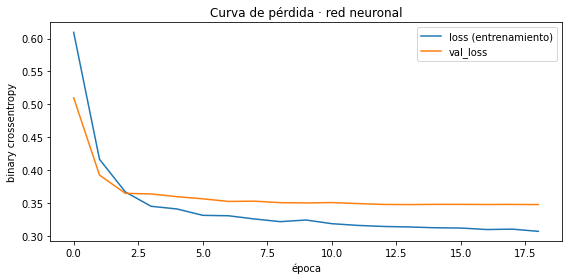

In [27]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
# Misma división por fecha y mismas variables procesadas de la Parte 2 (preprocesador ajustado solo con entrenamiento)
prep_nn = crear_preprocesador().fit(X_tr, y_tr)
A_tr = prep_nn.transform(X_tr); A_va = prep_nn.transform(X_va)
A_tr = A_tr.toarray() if hasattr(A_tr, "toarray") else A_tr
A_va = A_va.toarray() if hasattr(A_va, "toarray") else A_va
red = keras.Sequential([
    keras.layers.Input(shape=(A_tr.shape[1],)),
    keras.layers.Dense(128, activation="relu"), keras.layers.BatchNormalization(), keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"), keras.layers.BatchNormalization(), keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid"),
])
red.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
# val_loss se monitorea sobre el último 20% (más reciente) del entrenamiento, no sobre la validación final
corte_nn = int(len(A_tr) * 0.8)
historia = red.fit(A_tr[:corte_nn], y_tr.values[:corte_nn], validation_data=(A_tr[corte_nn:], y_tr.values[corte_nn:]),
                   epochs=60, batch_size=512, callbacks=[parada], verbose=0)
prob_nn = red.predict(A_va, verbose=0).ravel()
resultados_nn = pd.DataFrame({"precision_en_10": {
    "Azar (tasa base)": resultados["Azar (tasa base)"], "Regla del retraso": resultados["Regla del retraso"],
    "Regresión logística": resultados["Regresión logística"], "XGBoost": resultados["XGBoost"],
    "Red neuronal (Keras)": precision_en_10(y_va, prob_nn)}})
resultados_nn["AUC"] = [np.nan, roc_auc_score(y_va, dias_de_retraso(X_va)), roc_auc_score(y_va, prob_lr), roc_auc_score(y_va, prob_xgb), roc_auc_score(y_va, prob_nn)]
print(f"Épocas entrenadas: {len(historia.history['loss'])} (mejor época: {int(np.argmin(historia.history['val_loss'])) + 1})")
display(resultados_nn.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historia.history["loss"], label="loss (entrenamiento)"); ax.plot(historia.history["val_loss"], label="val_loss")
ax.set_xlabel("época"); ax.set_ylabel("binary crossentropy"); ax.set_title("Curva de pérdida · red neuronal"); ax.legend()
plt.tight_layout(); plt.show()

**Resultado.** La red (`Dense 128 → BatchNorm → Dropout 0.3 → Dense 64 → BatchNorm → Dropout 0.3 → sigmoide`, Adam, `binary_crossentropy`, `EarlyStopping(patience=5)`) entrenó 19 épocas y se quedó con los pesos de la época 14. En validación logra `precision_en_10` = **0.4819** (AUC 0.7516), contra **0.4884** de XGBoost (AUC 0.7400) y 0.4664 de la regresión logística (AUC 0.7498).

**¿Por qué gana XGBoost en el 10% superior?** Los datos son tabulares y heterogéneos: unas pocas variables numéricas con escalas muy distintas, muchas categorías one-hot (estados, categorías) y una relación con **umbrales abruptos**: el riesgo salta cuando `dias_retraso` pasa de 0 (la tasa de mala reseña pasa de 0.0943 a 0.5720). Los árboles representan ese salto con un solo corte y combinan reglas del tipo "tarde **y** varios vendedores **y** categoría X", mientras que la red tiene que aproximarlo con funciones suaves y necesita más datos y ajuste. La red logra un AUC algo mayor (ordena bien el conjunto completo), pero XGBoost concentra mejor a los clientes más riesgosos, que es lo que paga el negocio (+0.0065 en `precision_en_10`). Además XGBoost es más rápido de entrenar, no necesita escalar las variables y su importancia de variables es fácil de explicar. Por eso el modelo desplegado es XGBoost.

## Parte 5 · Despliegue

- URL de la API en Render: **[pegar aquí]**
- URL de la app de Streamlit: **[pegar aquí]**

Versiones de este entorno (para su `requirements.txt` de la API):

In [28]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==2.3.3
numpy==2.2.6
scikit-learn==1.7.2
xgboost==3.2.0


In [29]:
import joblib as _jl, fastapi, pydantic, uvicorn
print(f"joblib=={_jl.__version__}")
requisitos_api = f"""fastapi=={fastapi.__version__}
uvicorn=={uvicorn.__version__}
pydantic=={pydantic.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
joblib=={_jl.__version__}
"""
with open("api/requirements.txt", "w") as f:
    f.write(requisitos_api)
print("api/requirements.txt:\n" + requisitos_api)

joblib==1.5.3
api/requirements.txt:
fastapi==0.162.0
uvicorn==0.52.1
pydantic==2.14.1
pandas==2.3.3
numpy==2.2.6
scikit-learn==1.7.2
xgboost==3.2.0
joblib==1.5.3



In [30]:
# Pedidos reales de ejemplo para la app (página "Riesgo de un pedido")
v_all = crear_variables(pedidos[ENTRADAS])
rng_sel = {
    "Entregado con mucho retraso (>10 días)": pedidos[v_all["dias_retraso"] > 10],
    "Entregado con retraso leve (1-3 días)": pedidos[v_all["dias_retraso"].between(1, 3)],
    "Entregado a tiempo (adelantado >10 días)": pedidos[v_all["dias_retraso"] < -10],
    "Varios vendedores": pedidos[pedidos["n_vendedores"] > 1],
    "Varios artículos del mismo vendedor": pedidos[(pedidos["n_items"] > 2) & (pedidos["n_vendedores"] == 1)],
    "Pedido caro (> 1,000 BRL)": pedidos[pedidos["precio_total"] > 1000],
    "Pago con boleto": pedidos[pedidos["tipo_pago"] == "boleto"],
    "Sin categoría ni fotos (faltantes)": pedidos[pedidos["categoria"].isna()],
}
ejemplos = []
for desc, sub in rng_sel.items():
    fila = sub.sort_values("order_purchase_timestamp").iloc[-1][ENTRADAS].copy()
    ejemplos.append({"descripcion": desc, **fila.to_dict()})
pedidos_ejemplo = pd.DataFrame(ejemplos)
pedidos_ejemplo["probabilidad_notebook"] = cargado.predict_proba(pedidos_ejemplo[ENTRADAS])[:, 1].round(4)
pedidos_ejemplo.to_csv("app/pedidos_ejemplo.csv", index=False)
display(pedidos_ejemplo[["descripcion", "order_id", "probabilidad_notebook"]])

,descripcion,order_id,probabilidad_notebook
0,Entregado con mucho retraso (>10 días),f1ec04b3b8679de55776bea7e3ad436f,0.7299
1,Entregado con retraso leve (1-3 días),6a07231081720ded5c208be252bdc004,0.7461
2,Entregado a tiempo (adelantado >10 días),00c763284c0056eed753352f5559ff0a,0.0820
3,Varios vendedores,9110751e359ba8d080caf6eaa34e7e8c,0.5366
4,Varios artículos del mismo vendedor,c950a394ee0369c853e3a1a55090e287,0.1545
5,"Pedido caro (> 1,000 BRL)",d2f270487125ddc41fd134c4003ad1d7,0.1462
6,Pago con boleto,7184582cfaaf35d73ad28fa85b7d8cd7,0.0941
7,Sin categoría ni fotos (faltantes),a56a69de5d08abcdd997b45a40cdbeed,0.1314


Prueba local obligatoria de la API (uvicorn en segundo plano + `requests`): GET `/`, POST `/riesgo` con un pedido real y POST con `precio_total = -10` (debe dar 422).

In [31]:
# Prueba local obligatoria de la API (antes de desplegar en Render)
import subprocess, sys, time, requests
servidor = subprocess.Popen([sys.executable, "-m", "uvicorn", "main:app", "--port", "8000"], cwd="api",
                            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        if requests.get("http://127.0.0.1:8000/", timeout=2).status_code == 200:
            break
    except requests.exceptions.RequestException:
        time.sleep(1)
r_get = requests.get("http://127.0.0.1:8000/", timeout=10)
print("GET /", r_get.status_code, r_get.json())
fila = pedidos.sort_values("order_purchase_timestamp").iloc[-1]
pedido_real = {k: (None if pd.isna(v) else (str(v) if isinstance(v, pd.Timestamp) else (v.item() if hasattr(v, "item") else v)))
               for k, v in fila[ENTRADAS].items()}
r_ok = requests.post("http://127.0.0.1:8000/riesgo", json=pedido_real, timeout=30)
print("POST /riesgo (pedido real)", r_ok.status_code, r_ok.json())
print("Probabilidad del notebook para el mismo pedido:", round(float(cargado.predict_proba(fila[ENTRADAS].to_frame().T)[:, 1][0]), 4))
r_bad = requests.post("http://127.0.0.1:8000/riesgo", json={**pedido_real, "precio_total": -10}, timeout=30)
print("POST /riesgo (precio_total = -10)", r_bad.status_code, r_bad.json()["detail"][0]["msg"])

GET / 200 {'status': 'ok', 'servicio': 'API de Riesgo Olist', 'modelo_cargado': True, 'umbral_riesgo_alto': 0.2677867114543915}
POST /riesgo (pedido real) 200 {'order_id': '00c763284c0056eed753352f5559ff0a', 'probabilidad': 0.082, 'riesgo_alto': False, 'umbral': 0.2678, 'recomendacion': 'No requiere llamada prioritaria'}
Probabilidad del notebook para el mismo pedido: 0.082
POST /riesgo (precio_total = -10) 422 Input should be greater than or equal to 0


Prueba de la API desplegada (debe devolver una probabilidad):

In [32]:
import requests
URL_API = "http://127.0.0.1:8000"  # reemplazar por la URL de Render al desplegar
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'order_id': 'bfbd0f9bdef84302105ad712db648a6c',
 'probabilidad': 0.8397,
 'riesgo_alto': True,
 'umbral': 0.2678,
 'recomendacion': 'Contactar al cliente inmediatamente'}

In [33]:
servidor.terminate(); servidor.wait(timeout=10)
print("Servidor local detenido")

Servidor local detenido


## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, solo el enlace o una copia.

## Uso de IA

Indiquen qué herramientas de IA usaron y para qué. Todo lo que entregan lo deben poder explicar en la defensa.

La ficha completa está en [`ficha_modelo.md`](ficha_modelo.md) (también en la página **Ficha del Modelo** de la app). Resumen: el modelo prioriza las llamadas preventivas al 10% de entregas con mayor riesgo de 1-2 estrellas (umbral 0.2678); en validación por fecha acierta en **48.8%** de las llamadas, frente a 11.9% al azar y 38.6% mirando solo el retraso; no debe usarse para sancionar vendedores; se recomienda supervisión humana y reentrenamiento mensual.

### Uso de IA de Proyecto_Final.ipynb

Usamos un asistente de IA (Devin, de Cognition AI) como apoyo para estructurar el código (consulta SQL con CTEs, `preparacion.py`, pipeline de scikit-learn, validación por fecha, pronóstico y clasificación de sentimiento), depurar errores de ejecución (por ejemplo, la serie con valores no positivos en Holt-Winters) y diseñar la API en FastAPI y la app multipágina en Streamlit. También ayudó a redactar las respuestas y la ficha.

Cómo validamos cada salida contra los datos reales:
- El contrato se verificó con la celda oficial: `Contrato completo: True | 77304 pedidos`.
- Todas las cifras de las respuestas en Markdown se tomaron de las salidas de las celdas ejecutadas.
- Revisamos que ninguna variable del modelo de riesgo ni de la red use información de la reseña.
- La API se probó en local: `GET /` = 200, `POST /riesgo` con un pedido real = 200 con la misma probabilidad que el notebook, y `precio_total = -10` = 422.
- Las traducciones y la clasificación de los desacuerdos se revisaron leyendo cada comentario en portugués.

Todo lo entregado lo entendemos y lo podemos explicar en la defensa.